# Notebook B: chia dữ liệu, mô hình và câu hỏi thứ ba

**Đề tài:** Số giờ cảnh báo trước hỏng máy nén của tàu metro dưới một hạn mức báo động giả và mức tô hồng của chia ngẫu nhiên trên MetroPT-3

**Sinh viên B** chạy sau khi Notebook A đã tạo file parquet, `sql/queries.sql` và `manifest.json`. Notebook này không cần kernel của Notebook A.

## Kiểm tra bàn giao

- **Làm gì:** đọc manifest và so mã băm của file parquet.
- **Vì sao:** bảo đảm hai notebook dùng đúng cùng một dữ liệu.
- **Kiểm tra:** ô in `handover ok`.

In [1]:
# run once per machine, then comment out
# %pip install pandas numpy duckdb pyarrow scikit-learn lightgbm xgboost matplotlib scipy
import os, json, hashlib, numpy as np, pandas as pd, warnings
warnings.filterwarnings('ignore')
m = json.load(open('data/processed/manifest.json'))
assert hashlib.md5(open(m['file'], 'rb').read()).hexdigest() == m['md5'], 'parquet differs from the manifest, rerun Notebook A'
os.makedirs('report', exist_ok=True); print('handover ok', m['rows'], 'rows')

handover ok 252720 rows


## Bước 4. Bảng đặc trưng và chia dữ liệu

- **Làm gì:** chạy lại `sql/queries.sql`, lấy bảng `feat`, chia tập huấn luyện và kiểm thử theo giao thức của đề tài.
- **Vì sao:** cách chia quyết định con số có đáng tin hay không; dòng `assert` là phép kiểm tra rò rỉ.
- **Kiểm tra:** ghi số dòng hai tập và số đặc trưng vào bảng mô tả thực nghiệm.

In [2]:
# Step 4: two time-ordered folds so that every reported failure is tested once; the main fold trains on the early months
import duckdb
con = duckdb.connect(); con.execute(open('sql/queries.sql').read())
feat = con.execute("SELECT * FROM feat ORDER BY ts").df()
X_cols = [c for c in feat.columns if c.endswith(('_mean', '_std', '_max', '_share', '_m15', '_m60', '_max60'))]
CUT = pd.Timestamp('2020-06-01')
def fold(early_train=True):                              # training period, validation tail of the training period, test period
    tr = feat[feat.ts < CUT] if early_train else feat[feat.ts >= CUT]; te = feat[feat.ts >= CUT] if early_train else feat[feat.ts < CUT]
    return tr, te
def fit_set(tr, n=60_000):                               # all target minutes and a sample of normal minutes
    pos = tr[tr.y == 1]; neg = tr[tr.y == 0]; return pd.concat([pos, neg.sample(min(n, len(neg)), random_state=0)]).sort_values('ts')
train_all, test = fold(True); train = fit_set(train_all)
X_tr, y_tr, X_te, y_te = train[X_cols], train.y, test[X_cols], test.y
assert train_all.ts.max() < test.ts.min() and y_tr.sum() > 0 and y_te.sum() > 0       # leakage check, both periods contain a failure
print(len(train), len(test), len(X_cols), 'features', 'target minutes train', int(y_tr.sum()), 'test', int(y_te.sum()))

62067 110163 37 features target minutes train 2067 test 3373


## Bước 4b. Hiểu tập huấn luyện và tập kiểm thử

Ba ô dưới đây kiểm tra hai tập có giống nhau không và đặc trưng nào mạnh nhất, trước khi huấn luyện bất kỳ mô hình nào.

### 4b.1 Mục tiêu ở hai tập

- **Làm gì:** so phân phối của mục tiêu giữa tập huấn luyện và tập kiểm thử.
- **Vì sao:** hai phân phối lệch nhau giải thích vì sao mô hình cây ngoại suy kém.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [3]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

import matplotlib.pyplot as plt
def nice(v, label):                                     # readable numbers on the bars
    v = np.asarray(v, dtype=float); m = np.nanmax(np.abs(v))
    return (v / 1e6, label + ' (million)', '{:.2f}') if m >= 1e6 else (v / 1e3, label + ' (thousand)', '{:.1f}') if m >= 1e4 else (v, label, '{:.2f}' if m < 100 else '{:.0f}')
ytr, yte = pd.Series(np.asarray(y_tr, dtype=float)), pd.Series(np.asarray(y_te, dtype=float)); BINARY = ytr.nunique() <= 2
print('train rows', len(ytr), 'test rows', len(yte), 'features', X_tr.shape[1])
if BINARY: print('positive share: train %.3f, test %.3f' % (ytr.mean(), yte.mean()))
else:
    fig, ax = plt.subplots(figsize=(6.5, 3)); lo, hi = min(ytr.quantile(.01), yte.quantile(.01)), max(ytr.quantile(.99), yte.quantile(.99)); bins = np.linspace(lo, hi, 50)
    ax.hist(ytr.clip(lo, hi), bins=bins, density=True, alpha=.6, color='#1B6B6D', label='Train'); ax.hist(yte.clip(lo, hi), bins=bins, density=True, alpha=.6, color='#F4A261', label='Test')
    ax.legend(frameon=False); ax.set_xlabel('Target'); ax.set_ylabel('Density'); ax.spines[['top', 'right']].set_visible(False); fig.tight_layout(); fig.savefig('report/fig_split_target.png', dpi=200); plt.show()
    print(pd.DataFrame({'train': ytr.describe(), 'test': yte.describe()}).round(3))

train rows 62067 test rows 110163 features 37
positive share: train 0.033, test 0.031


### 4b.2 Đặc trưng lệch giữa hai tập

- **Làm gì:** độ lệch trung bình chuẩn hoá của từng đặc trưng giữa hai tập.
- **Kiểm tra:** đặc trưng lệch trên 0,5 độ lệch chuẩn là nguồn rủi ro, nêu trong mục Limitations.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [4]:
A_, B_ = X_tr.astype(float), X_te.astype(float); sd = A_.std().replace(0, np.nan)
shift = ((B_.mean() - A_.mean()) / sd).abs().sort_values(ascending=False).rename('abs_standardised_mean_difference')
shift.to_csv('report/table_split_shift.csv'); display(shift.head(10).round(3).to_frame())
print('features whose test mean lies more than 0.5 training standard deviations away:', int((shift > 0.5).sum()), 'of', len(shift))

,abs_standardised_mean_difference
Oil_level_share,1.835
Oil_m60,0.990
Oil_m15,0.938
Oil_temperature_max,0.849
Oil_temperature_mean,0.844
Motor_m15,0.360
Caudal_impulses_share,0.304
Motor_current_max,0.244
Motor_current_mean,0.236
Oil_temperature_std,0.234


features whose test mean lies more than 0.5 training standard deviations away: 5 of 37


### 4b.3 Sức mạnh của từng đặc trưng

- **Làm gì:** tương quan hạng giữa từng đặc trưng và mục tiêu trên tập huấn luyện.
- **Vì sao:** nếu một đặc trưng đã gần đủ, mô hình phức tạp sẽ không hơn nhiều, và đó là thông tin để chọn câu hỏi.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [5]:
sig = A_.sample(min(len(A_), 20_000), random_state=0); ys = pd.Series(np.asarray(y_tr, dtype=float), index=X_tr.index).loc[sig.index]
strength = sig.corrwith(ys, method='spearman').abs().sort_values(ascending=False).rename('abs_rank_correlation_with_target')
strength.to_csv('report/table_feature_strength.csv'); display(strength.head(10).round(3).to_frame())
print('strongest single feature:', strength.index[0], round(float(strength.iloc[0]), 3), '-> a model must beat what this feature already gives')

,abs_rank_correlation_with_target
COMP_share,0.367
MPG_share,0.363
DV_eletric_share,0.354
Towers_share,0.347
COMP_m60,0.293
H1_std,0.262
TP3_m60,0.256
H1_max,0.253
DV_pressure_mean,0.251
H1_mean,0.249


strongest single feature: COMP_share 0.367 -> a model must beat what this feature already gives


## Bước 6a. So sánh mô hình (RQ2)

- **Làm gì:** huấn luyện mười mô hình với năm seed trên cùng cách chia.
- **Vì sao:** so nhiều họ mô hình để kết luận không phụ thuộc một kiểu mô hình; năm seed cho độ lệch chuẩn.
- **Kiểm tra:** chênh lệch nhỏ hơn độ lệch chuẩn thì chưa được kết luận mô hình nào hơn. Bảng lưu ở `report/table_rq2.csv`.

In [6]:
# Step 6a: ten classifiers from four families, five seeds, trained on the first months and tested on the later months; probability metrics because one class is rare
import numpy as np, pandas as pd, time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
sc = lambda m: make_pipeline(StandardScaler(), m)       # scaling for linear, distance and neural models
models = {
    'Logistic':       lambda s: sc(LogisticRegression(max_iter=500, random_state=s)),
    'Linear SVM':     lambda s: sc(LinearSVC(C=1.0, random_state=s)),
    'k-NN':           lambda s: sc(KNeighborsClassifier(n_neighbors=15)),
    'Decision Tree':  lambda s: DecisionTreeClassifier(max_depth=12, min_samples_leaf=5, random_state=s),
    'Random Forest':  lambda s: RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=s),
    'Extra Trees':    lambda s: ExtraTreesClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=s),
    'HistGB':         lambda s: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=s),
    'LightGBM':       lambda s: LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
                                               subsample_freq=1, colsample_bytree=0.8, random_state=s, verbose=-1),
    'XGBoost':        lambda s: XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8,
                                              colsample_bytree=0.8, tree_method='hist', random_state=s),
    'Small MLP':      lambda s: sc(MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=200, early_stopping=True,
                                                 random_state=s)),
}
def proba(m, X):                                        # probability of the positive class for every model family
    if hasattr(m, 'predict_proba'): return m.predict_proba(X)[:, 1]
    return 1 / (1 + np.exp(-m.decision_function(X)))
rows, fitted = [], {}
for name, make in models.items():
    aucs, aps, briers, secs = [], [], [], []
    for seed in range(5):
        m = make(seed); t0 = time.perf_counter(); m.fit(X_tr, y_tr); secs.append(time.perf_counter() - t0)
        p = proba(m, X_te); aucs.append(roc_auc_score(y_te, p)); aps.append(average_precision_score(y_te, p))
        briers.append(brier_score_loss(y_te, p))
    fitted[name] = m                                    # keep the last fitted model of each family for Step 6b
    rows.append([name, np.mean(aucs), np.std(aucs), np.mean(aps), np.mean(briers), np.mean(secs)])
res = pd.DataFrame(rows, columns=['model', 'ROC_AUC', 'sd', 'PR_AUC', 'Brier', 'train_s'])
res.to_csv('report/table_rq2.csv', index=False); print(res.round(4))

           model  ROC_AUC      sd  PR_AUC   Brier  train_s
0       Logistic   0.8799  0.0000  0.7156  0.0152   0.3471
1     Linear SVM   0.8661  0.0000  0.6795  0.0589   0.6714
2           k-NN   0.5751  0.0000  0.1158  0.0291   0.0640
3  Decision Tree   0.6450  0.0002  0.2644  0.0253   0.7398
4  Random Forest   0.9529  0.0036  0.5986  0.0229   4.0796
5    Extra Trees   0.9600  0.0011  0.7247  0.0204   1.2957
6         HistGB   0.7755  0.0401  0.3329  0.0254   0.5456
7       LightGBM   0.8824  0.0109  0.3852  0.0234   0.8489
8        XGBoost   0.9145  0.0064  0.3770  0.0247   1.4563
9      Small MLP   0.6114  0.0870  0.2867  0.0256   3.4946


### Hình RQ2

- **Làm gì:** vẽ kết quả các mô hình, tô màu nhấn mô hình tốt nhất.
- **Kiểm tra:** số trên cột khớp với `report/table_rq2.csv`.

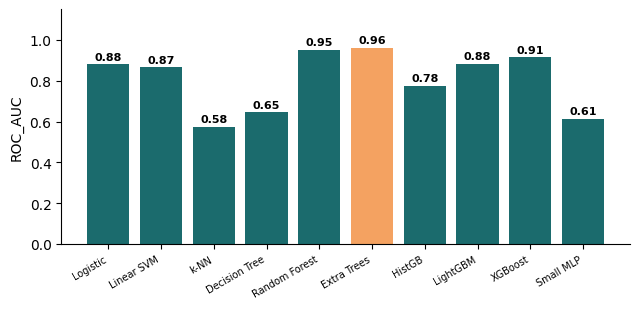

In [7]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

bar_chart(res.model, res.iloc[:, 1], res.columns[1], 'report/fig_rq2_models.png', highlight=int(res.iloc[:, 1].idxmax()), fmt='{:.2f}')

## Cổng khả thi: có nên xoay câu hỏi không

- **Làm gì:** so mô hình tốt nhất với mốc đơn giản và in ra một trong ba kết luận.
- **Vì sao:** nếu mô hình không hơn mốc hoặc bài toán quá dễ, nhóm xoay câu hỏi ngay ở đây thay vì cố chỉnh mô hình. Xoay câu hỏi nghĩa là đổi điều được hỏi cho khớp với điều dữ liệu trả lời được, không phải chọn lại số liệu cho đẹp.

**Các hướng xoay của đề tài này:**

1. Nếu chỉ một hai sự kiện được báo trước: trình bày từng sự kiện như nghiên cứu trường hợp, không tính trung bình.
2. Nếu chia theo thời gian cho điểm thấp: giữ làm kết quả chính và đặt cạnh điểm của chia ngẫu nhiên, mức chênh là đóng góp.
3. Nếu tín hiệu số (COMP, LPS) đã đủ: đổi RQ3 thành so bộ đặc trưng tối thiểu với bộ đầy đủ.

**Quyết định của nhóm (giữ câu hỏi hay xoay theo hướng nào, vì sao):** ...

In [8]:
best = res.sort_values('ROC_AUC').iloc[-1]; spread = res.ROC_AUC.max() - res.ROC_AUC.min()
print('best model %s: ROC-AUC %.4f, PR-AUC %.4f | spread between models %.4f' % (best.model, best.ROC_AUC, best.PR_AUC, spread))
verdict = 'TOO EASY: every model is near the ceiling, so the comparison says little; explain why the task is easy or use a harder protocol (RQ3)' if best.ROC_AUC >= 0.995 else 'GOOD: there is a clear signal and room to compare models' if best.ROC_AUC >= 0.75 else 'WEAK: the signal is weak, pivot the target or the features (see the options above) and report this result honestly'
print(verdict); pd.Series({'best_model': best.model, 'ROC_AUC': best.ROC_AUC, 'PR_AUC': best.PR_AUC, 'spread': spread, 'verdict': verdict}).to_csv('report/table_feasibility_gate.csv')

best model Extra Trees: ROC-AUC 0.9600, PR-AUC 0.7247 | spread between models 0.3848
GOOD: there is a clear signal and room to compare models


## Bước 6b. Câu hỏi thứ ba (RQ3)

- **Làm gì:** Huấn luyện lại mười mô hình dưới chia ngẫu nhiên và bốn mô hình đại diện trên hai nếp gấp theo thời gian để chấm theo sự kiện.
- **Vì sao:** đây là đóng góp chính của bài; mỗi bảng `report/table_rq3_*.csv` ứng với một ý trong mục Results.
- **Kiểm tra:** đọc từng bảng in ra và viết một câu kết luận có số cho mỗi bảng. Nếu kết quả trái dự kiến trong đề cương thì báo đúng như vậy và tìm nguyên nhân, không chỉnh code cho ra kết quả mong muốn.

In [10]:
# Step 6b: RQ3, how many hours of warning before each reported failure under a false-alarm budget, and how much does a random split flatter?
FAIL = [('2020-04-18 00:00', '2020-04-18 23:59'), ('2020-05-29 23:30', '2020-05-30 06:00'),   # four air leaks reported by the operator (UCI page)
        ('2020-06-05 10:00', '2020-06-07 14:30'), ('2020-07-15 14:30', '2020-07-15 19:00')]
FAIL = [(pd.Timestamp(a), pd.Timestamp(b)) for a, b in FAIL]
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
rows = []; pool = fit_set(feat, 120_000)
A, B = train_test_split(pool, test_size=0.2, random_state=0, stratify=pool.y)      # (1) random minutes: neighbours of a test minute sit in training
sub = test.sample(min(60_000, len(test)), random_state=0)
for name, make in models.items():
    p = proba(make(0).fit(A[X_cols], A.y), B[X_cols]); q = proba(fitted[name], sub[X_cols])
    rows.append([name, f1_score(B.y, p >= 0.5), average_precision_score(B.y, p), f1_score(sub.y, q >= 0.5), average_precision_score(sub.y, q)])
infl = pd.DataFrame(rows, columns=['model', 'F1_random', 'PR_AUC_random', 'F1_time_ordered', 'PR_AUC_time_ordered'])
infl['F1_inflation'] = infl.F1_random - infl.F1_time_ordered; infl.to_csv('report/table_rq3_split_inflation.csv', index=False); print(infl.round(3))
# (2) event level: an alarm needs 5 consecutive minutes above the threshold; the threshold is the lowest one that keeps false alarms within the budget
def episodes(flag, ts):                                  # start times of alarm episodes (alarms less than one hour apart count once)
    t = ts[flag]; return t[(t.diff().dt.total_seconds().fillna(1e9) > 3600).to_numpy()] if len(t) else t
def run_alarm(p, d, thr): return pd.Series(p >= thr).rolling(5, min_periods=5).min().fillna(0).to_numpy() == 1
def score_events(d, alarm):
    near = np.zeros(len(d), bool); out = []
    for i, (a, b) in enumerate(FAIL, 1):
        if not d.ts.between(a, b).any(): continue
        win = d.ts.between(a - pd.Timedelta(hours=24), b).to_numpy(); near |= win
        first = d.ts[win & alarm]; out.append([i, bool(len(first)), (a - first.iloc[0]).total_seconds() / 3600 if len(first) else np.nan])
    weeks = max(1e-9, (~near).sum() / (60 * 24 * 7)); return out, len(episodes(alarm & ~near, d.ts)) / weeks
FAM = ['Logistic', 'Random Forest', 'LightGBM', 'Small MLP']; BUDGETS = [1, 3, 7]; rows = []
for early in [True, False]:
    tr, te = fold(early); cutv = tr.ts.quantile(0.7); fit, val = fit_set(tr[tr.ts <= cutv]), tr[tr.ts > cutv]
    if fit.y.sum() == 0: fit, val = fit_set(tr[tr.ts > tr.ts.quantile(0.3)]), tr[tr.ts <= tr.ts.quantile(0.3)]      # keep a failure in the fitting part
    for name in FAM:
        m = models[name](0).fit(fit[X_cols], fit.y); pv, pt = proba(m, val[X_cols]), proba(m, te[X_cols])
        for budget in BUDGETS:
            thr = next((t for t in np.quantile(pv, np.linspace(0.5, 0.9999, 60)) if score_events(val, run_alarm(pv, val, t))[1] <= budget), pv.max() + 1e-9)
            ev, fa = score_events(te, run_alarm(pt, te, thr))
            rows += [['early months' if early else 'late months', name, budget, e, det, lead, fa] for e, det, lead in ev]
evt = pd.DataFrame(rows, columns=['trained_on', 'model', 'budget_per_week', 'failure', 'detected', 'lead_hours', 'false_alarms_per_week_test'])
evt.to_csv('report/table_rq3_event_level.csv', index=False)
print(evt.pivot_table(index=['failure', 'budget_per_week'], columns='model', values='lead_hours').round(1))

           model  F1_random  PR_AUC_random  F1_time_ordered  \
0       Logistic      0.829          0.874            0.576   
1     Linear SVM      0.821          0.836            0.528   
2           k-NN      0.938          0.964            0.097   
3  Decision Tree      0.968          0.971            0.402   
4  Random Forest      0.968          0.994            0.031   
5    Extra Trees      0.962          0.984            0.008   
6         HistGB      0.982          0.998            0.329   
7       LightGBM      0.986          0.999            0.398   
8        XGBoost      0.981          0.999            0.191   
9      Small MLP      0.945          0.978            0.204   

   PR_AUC_time_ordered  F1_inflation  
0                0.709         0.252  
1                0.674         0.293  
2                0.109         0.841  
3                0.257         0.567  
4                0.584         0.937  
5                0.711         0.954  
6                0.383         0.

## Bước 6c. Kiểm tra bổ sung và bảng tham số

- **Làm gì:** chạy phép kiểm tra bổ sung của đề tài và lưu tham số mô hình.
- **Vì sao:** bảng này đi vào phần thảo luận và phụ lục của bài.
- **Kiểm tra:** `report/params_best.json` tồn tại.

In [11]:
# Step 6c: summary per false-alarm budget, the effect of frozen-logger minutes, and parameters
summ = evt.groupby(['budget_per_week', 'model']).agg(failures_detected=('detected', 'sum'), failures=('detected', 'size'), median_lead_hours=('lead_hours', 'median'),
                                                    false_alarms_per_week=('false_alarms_per_week_test', 'mean')).reset_index()
summ.to_csv('report/table_rq3_budget_summary.csv', index=False); print(summ.round(2))
best = res.sort_values('PR_AUC').model.iloc[-1]; keep = test.frozen == 0; p = proba(fitted[best], X_te)
frz = pd.Series({'test_minutes': len(test), 'frozen_minutes': int((~keep).sum()), 'PR_AUC_all': average_precision_score(y_te, p),
                 'PR_AUC_without_frozen': average_precision_score(y_te[keep], p[keep.to_numpy()]), 'target_share_in_frozen': float(y_te[~keep].mean()) if (~keep).any() else np.nan})
frz.rename('value').to_csv('report/table_rq3_frozen_logger.csv'); print(best); print(frz.round(4))
import json
json.dump({'best': best, 'horizon_hours': 2, 'budgets_per_week': BUDGETS, 'params': {k: str(v) for k, v in models[best](0).get_params().items()}}, open('report/params_best.json', 'w'), indent=2)

    budget_per_week          model  failures_detected  failures  \
0                 1       LightGBM                  3         4   
1                 1       Logistic                  3         4   
2                 1  Random Forest                  3         4   
3                 1      Small MLP                  3         4   
4                 3       LightGBM                  3         4   
5                 3       Logistic                  4         4   
6                 3  Random Forest                  3         4   
7                 3      Small MLP                  3         4   
8                 7       LightGBM                  4         4   
9                 7       Logistic                  4         4   
10                7  Random Forest                  4         4   
11                7      Small MLP                  3         4   

    median_lead_hours  false_alarms_per_week  
0               -0.27                   0.45  
1               -0.28             

### Hình RQ3

- **Làm gì:** vẽ hai hình RQ3 từ các bảng `report/table_rq3_*.csv` bằng hàm `bar_chart` ở trên, theo mẫu Hình 4 và Hình 5 của đề cương.
- **Kiểm tra:** mỗi hình một ý, chữ tiếng Anh, số in đậm trên cột.

report\table_rq3_budget_summary.csv (12, 6)


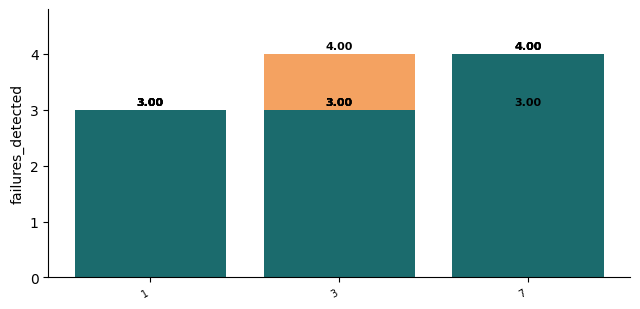

report\table_rq3_event_level.csv (48, 7)
report\table_rq3_frozen_logger.csv (5, 2)


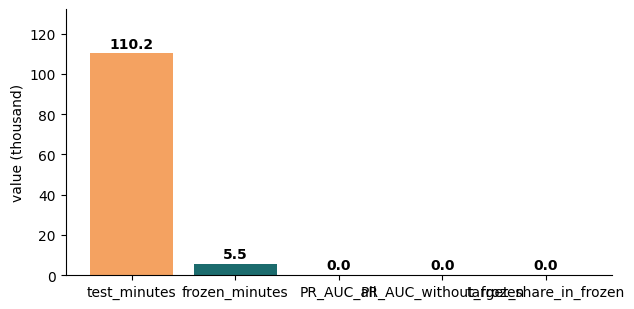

report\table_rq3_split_inflation.csv (10, 6)


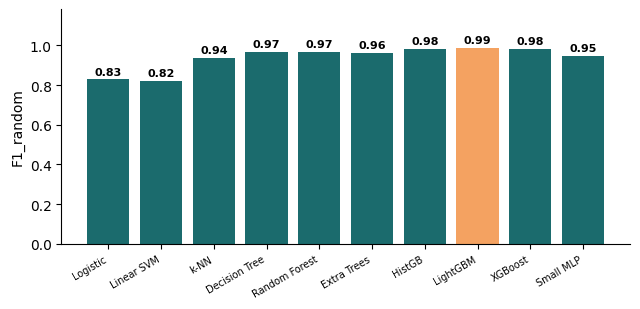

In [12]:
import glob
for f in sorted(glob.glob('report/table_rq3_*.csv')):
    t = pd.read_csv(f); numc = [c for c in t.columns[1:] if pd.api.types.is_numeric_dtype(t[c])]
    print(f, t.shape)
    if 2 <= len(t) <= 14 and numc and t[numc[0]].notna().all() and t[numc[0]].min() >= 0 and t[numc[0]].max() > 0:
        v, lab, fm = nice(t[numc[0]], numc[0]); bar_chart(t.iloc[:, 0].astype(str), v, lab, f.replace('table_', 'fig_').replace('.csv', '.png'), highlight=int(v.argmax()), fmt=fm)

## Test case và chẩn đoán

- **Làm gì:** kiểm tra tự động các sản phẩm của notebook.
- **Kiểm tra:** mọi `assert` qua. Sinh viên A chạy lại notebook này và ghi vào ô Đối chứng.

In [13]:
assert os.path.exists('report/table_rq2.csv') and os.path.exists('report/params_best.json')
assert len(glob.glob('report/table_rq3_*.csv')) >= 2, 'RQ3 tables missing'
assert res.iloc[:, 1].notna().all()
print(sorted(os.path.basename(f) for f in glob.glob('report/*')))
print('Notebook B: all checks passed')

['fig_eda_by_group.png', 'fig_eda_correlation.png', 'fig_eda_distributions.png', 'fig_eda_heatmap.png', 'fig_eda_target.png', 'fig_q1.png', 'fig_q2.png', 'fig_q3.png', 'fig_q4.png', 'fig_q7.png', 'fig_rq1.png', 'fig_rq2_models.png', 'fig_rq3_budget_summary.png', 'fig_rq3_frozen_logger.png', 'fig_rq3_split_inflation.png', 'params_best.json', 'table_cleaning_log.csv', 'table_data_dictionary.csv', 'table_eda_by_group.csv', 'table_eda_correlation.csv', 'table_feasibility_gate.csv', 'table_feature_strength.csv', 'table_numeric_summary.csv', 'table_outliers.csv', 'table_q1.csv', 'table_q2.csv', 'table_q3.csv', 'table_q4.csv', 'table_q5.csv', 'table_q6.csv', 'table_q7.csv', 'table_q8.csv', 'table_rq2.csv', 'table_rq3_budget_summary.csv', 'table_rq3_event_level.csv', 'table_rq3_frozen_logger.csv', 'table_rq3_split_inflation.csv', 'table_split_shift.csv']
Notebook B: all checks passed


### Đối chứng

| Người chạy lại | Ngày | Metric chính khớp | Ghi chú |
|---|---|---|---|
| | | | |

### Chẩn đoán

Nếu mô hình tốt nhất không hơn mốc đơn giản hoặc kết quả RQ3 trái dự kiến, ghi nguyên nhân có bằng chứng (thiếu đặc trưng, dữ liệu ít, lệch giữa hai tập) vào `report/table_diagnosis.csv`.

### Báo cáo tiến độ (dán vào kênh nhóm trước buổi báo cáo)

1. Việc đã xong, kèm tên file và số dòng, bảng, hình:
2. Con số chính mới có:
3. Vướng mắc và điều đã thử:
4. Việc sẽ làm đến lần báo cáo sau, ai làm:
5. Prompt AI đáng chú ý và Human Delta: